# 03. A/B Test — Statistical Analysis

## Цель

Оценить, насколько убедительно данные поддерживают гипотезу о повышении конверсии после запуска упрощённой формы оплаты ЖКХ.

**Единица рандомизации — пользователь.** Основная метрика из задания — доля пользователей с успешной оплатой среди пользователей, открывших форму. Дополнительно считаем ITT-метрику среди всех пользователей с известной назначенной группой: она не обусловлена фактом открытия формы.

### Гипотезы для основной метрики

- `H0`: конверсия B равна конверсии A.
- `H1`: конверсии различаются.

## 1. Импорт библиотек и загрузка витрин

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest, chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from IPython.display import display

pd.set_option('display.max_columns', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

ROOT_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
PROJECT_ROOT = next((p for p in ROOT_CANDIDATES if (p / 'data/processed/users_mart.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Не найдены data/processed/*.csv. Сначала выполните 01_data_audit.ipynb.')

users = pd.read_csv(PROJECT_ROOT / 'data/processed/users_mart.csv')
for c in ['opened_any','entered_any','confirmed_any','success_any','group_eligible','funnel_eligible']:
    users[c] = users[c].astype(str).str.lower().map({'true': True, 'false': False}).fillna(False).astype(bool)
users_ab = users.loc[users['assigned_group'].isin(['A','B'])].copy()

print(f'Проект: {PROJECT_ROOT}')
print(f'Всего пользователей с известной группой: {len(users_ab):,}')
print(users_ab['assigned_group'].value_counts().reindex(['A','B']))
assert users_ab['user_id'].is_unique

Проект: <project_root>
Всего пользователей с известной группой: 1,503
assigned_group
A    752
B    751
Name: count, dtype: int64


## 2. Вспомогательные функции для долей и доверительных интервалов

In [ ]:
def wilson_interval(successes: int, trials: int, alpha: float = 0.05):
    if trials <= 0:
        return (np.nan, np.nan)
    z = norm.ppf(1 - alpha/2)
    p = successes / trials
    denom = 1 + z**2 / trials
    center = (p + z**2/(2*trials)) / denom
    half = z * np.sqrt(p*(1-p)/trials + z**2/(4*trials**2)) / denom
    return (center-half, center+half)


def newcombe_diff_interval(x_a: int, n_a: int, x_b: int, n_b: int, alpha: float = 0.05):
    p_a, p_b = x_a/n_a, x_b/n_b
    l_a, u_a = wilson_interval(x_a, n_a, alpha)
    l_b, u_b = wilson_interval(x_b, n_b, alpha)
    diff = p_b - p_a
    lower = diff - np.sqrt((p_b-l_b)**2 + (u_a-p_a)**2)
    upper = diff + np.sqrt((u_b-p_b)**2 + (p_a-l_a)**2)
    return diff, lower, upper


def compare_two_proportions(x_a, n_a, x_b, n_b, alpha=0.05):
    p_a, p_b = x_a/n_a, x_b/n_b
    pooled = (x_a+x_b)/(n_a+n_b)
    se0 = np.sqrt(pooled*(1-pooled)*(1/n_a+1/n_b))
    z_stat = (p_b-p_a)/se0 if se0 > 0 else np.nan
    p_value = 2*norm.sf(abs(z_stat)) if np.isfinite(z_stat) else np.nan
    diff, ci_low, ci_high = newcombe_diff_interval(x_a,n_a,x_b,n_b,alpha)
    return {'n_A':n_a,'success_A':x_a,'cr_A':p_a,'ci_A_low':wilson_interval(x_a,n_a,alpha)[0],
            'ci_A_high':wilson_interval(x_a,n_a,alpha)[1],
            'n_B':n_b,'success_B':x_b,'cr_B':p_b,'ci_B_low':wilson_interval(x_b,n_b,alpha)[0],
            'ci_B_high':wilson_interval(x_b,n_b,alpha)[1],
            'absolute_lift_B_minus_A':diff,'ci_diff_low':ci_low,'ci_diff_high':ci_high,
            'relative_lift':(p_b/p_a-1) if p_a else np.nan,'z_stat':z_stat,'p_value':p_value}

ALPHA = 0.05

## 3. Основная метрика: успешная оплата среди открывших форму

In [3]:
primary_base = users_ab.loc[users_ab['opened_any']].copy()
counts = {}
for group in ['A','B']:
    g = primary_base.loc[primary_base['assigned_group'].eq(group)]
    counts[group] = (int(g['success_any'].sum()), len(g))

primary = compare_two_proportions(*counts['A'], *counts['B'], alpha=ALPHA)
primary_summary = pd.DataFrame([
    {'metric':'Основная конверсия (от открытия)','value_A':primary['cr_A'],'value_B':primary['cr_B'],
     'absolute_lift_pp':primary['absolute_lift_B_minus_A']*100,
     'relative_lift_pct':primary['relative_lift']*100,
     'ci_diff_low_pp':primary['ci_diff_low']*100,'ci_diff_high_pp':primary['ci_diff_high']*100,
     'p_value':primary['p_value']}
])
display(primary_summary.style.format({
    'value_A':'{:.2%}','value_B':'{:.2%}','absolute_lift_pp':'{:+.2f}',
    'relative_lift_pct':'{:+.1f}','ci_diff_low_pp':'{:+.2f}',
    'ci_diff_high_pp':'{:+.2f}','p_value':'{:.3e}'
}))

print(f"A: {primary['success_A']}/{primary['n_A']} = {primary['cr_A']:.2%}")
print(f"B: {primary['success_B']}/{primary['n_B']} = {primary['cr_B']:.2%}")
print(f"Абсолютный эффект B − A: {primary['absolute_lift_B_minus_A']*100:+.2f} п.п.")
print(f"95% CI эффекта: [{primary['ci_diff_low']*100:+.2f}; {primary['ci_diff_high']*100:+.2f}] п.п.")
print(f"p-value: {primary['p_value']:.3e}")

,metric,value_A,value_B,absolute_lift_pp,relative_lift_pct,ci_diff_low_pp,ci_diff_high_pp,p_value
0,Основная конверсия (от открытия),65.78%,80.40%,+14.62,+22.2,+10.16,+19.00,1.703e-10


A: 494/751 = 65.78%
B: 603/750 = 80.40%
Абсолютный эффект B − A: +14.62 п.п.
95% CI эффекта: [+10.16; +19.00] п.п.
p-value: 1.703e-10


### Визуализация основной метрики

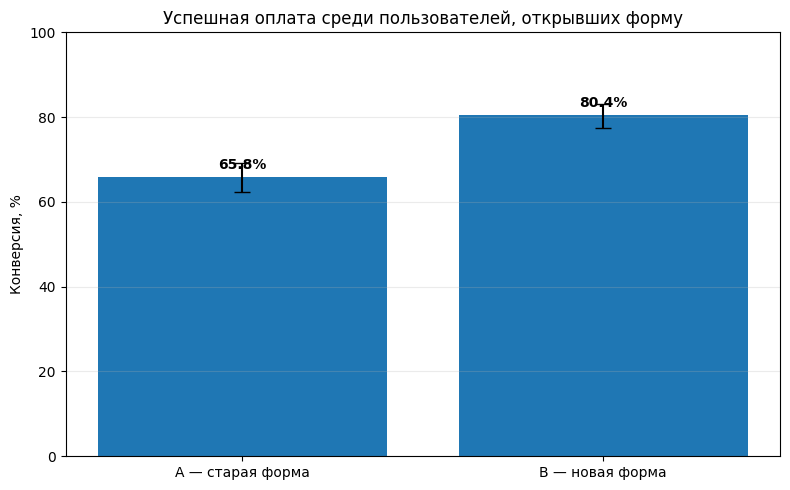

In [4]:
labels = ['A — старая форма','B — новая форма']
values = [primary['cr_A']*100, primary['cr_B']*100]
errors = [
    [(primary['cr_A']-primary['ci_A_low'])*100, (primary['cr_B']-primary['ci_B_low'])*100],
    [(primary['ci_A_high']-primary['cr_A'])*100, (primary['ci_B_high']-primary['cr_B'])*100]
]
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(labels, values, yerr=errors, capsize=6)
ax.set_ylabel('Конверсия, %')
ax.set_title('Успешная оплата среди пользователей, открывших форму')
ax.set_ylim(0,100)
ax.grid(axis='y', alpha=.25)
for i,v in enumerate(values): ax.text(i,v+2,f'{v:.1f}%',ha='center',fontweight='bold')
plt.tight_layout(); plt.show()

## 4. Дополнительная оценка: ITT

In [5]:
itt_counts = {}
for group in ['A','B']:
    g = users_ab.loc[users_ab['assigned_group'].eq(group)]
    itt_counts[group] = (int(g['success_any'].sum()), len(g))
itt = compare_two_proportions(*itt_counts['A'], *itt_counts['B'], alpha=ALPHA)
itt_summary = pd.DataFrame([
    {'metric':'ITT: успешная оплата / все назначенные','cr_A':itt['cr_A'],'cr_B':itt['cr_B'],
     'absolute_lift_pp':itt['absolute_lift_B_minus_A']*100,
     'ci_low_pp':itt['ci_diff_low']*100,'ci_high_pp':itt['ci_diff_high']*100,'p_value':itt['p_value']}
])
display(itt_summary.style.format({'cr_A':'{:.2%}','cr_B':'{:.2%}','absolute_lift_pp':'{:+.2f}',
                                  'ci_low_pp':'{:+.2f}','ci_high_pp':'{:+.2f}','p_value':'{:.3e}'}))

,metric,cr_A,cr_B,absolute_lift_pp,ci_low_pp,ci_high_pp,p_value
0,ITT: успешная оплата / все назначенные,65.69%,80.29%,+14.60,+10.14,+18.99,1.837e-10


## 5. Проверка SRM

Ниже приведена проверка гипотезы 50/50 

In [6]:
assigned_counts = users_ab['assigned_group'].value_counts().reindex(['A','B'], fill_value=0)
n_a, n_b = int(assigned_counts['A']), int(assigned_counts['B'])
srm = binomtest(n_a, n_a+n_b, p=0.5, alternative='two-sided')
srm_summary = pd.DataFrame([{
    'A_users':n_a,'B_users':n_b,'A_share':n_a/(n_a+n_b),
    'expected_share_assumption':0.5,'exact_binomial_p_value':srm.pvalue
}])
display(srm_summary.style.format({'A_share':'{:.2%}','expected_share_assumption':'{:.0%}','exact_binomial_p_value':'{:.4f}'}))
print('Интерпретация применима только при подтверждённом распределении 50/50.')

,A_users,B_users,A_share,expected_share_assumption,exact_binomial_p_value
0,752,751,50.03%,50%,1.0000


Интерпретация применима только при подтверждённом распределении 50/50.


## 6. Исследовательская проверка переходов между этапами

Для каждого перехода сравниваем долю пользователей, дошедших до следующего этапа, среди достигших предыдущего. 

In [7]:
stages = [('opened_any','entered_any','Открытие → ввод'),
          ('entered_any','confirmed_any','Ввод → подтверждение'),
          ('confirmed_any','success_any','Подтверждение → успех')]
transition_rows=[]
for prev_col,next_col,label in stages:
    vals=[]
    for group in ['A','B']:
        g=users_ab[(users_ab.assigned_group==group)&(users_ab[prev_col])]
        vals.append((int(g[next_col].sum()),len(g)))
    test=compare_two_proportions(*vals[0],*vals[1],alpha=ALPHA)
    transition_rows.append({'transition':label,'n_A':test['n_A'],'rate_A':test['cr_A'],
                            'n_B':test['n_B'],'rate_B':test['cr_B'],
                            'lift_pp':test['absolute_lift_B_minus_A']*100,
                            'p_value':test['p_value']})
transition_tests=pd.DataFrame(transition_rows)
transition_tests['p_value_holm']=multipletests(transition_tests['p_value'],method='holm')[1]
display(transition_tests.style.format({'rate_A':'{:.1%}','rate_B':'{:.1%}','lift_pp':'{:+.2f}',
                                       'p_value':'{:.3e}','p_value_holm':'{:.3e}'}))

,transition,n_A,rate_A,n_B,rate_B,lift_pp,p_value,p_value_holm
0,Открытие → ввод,751,89.5%,750,94.3%,+4.79,6.920e-04,1.384e-03
1,Ввод → подтверждение,672,81.7%,707,91.1%,+9.39,3.330e-07,9.990e-07
2,Подтверждение → успех,549,90.0%,644,93.6%,+3.65,2.083e-02,2.083e-02


## 7. MDE и чувствительность фактической выборки

MDE оценивает минимальную разницу долей, которую текущая выборка могла бы обнаружить с заданной мощностью при выбранных alpha и базовой конверсии.

In [8]:
power_analysis=NormalIndPower()
n_a,n_b=primary['n_A'],primary['n_B']
p_baseline=primary['cr_A']
target_power=0.80

def estimated_power_for_abs_effect(delta):
    p_new=min(max(p_baseline+delta,1e-6),1-1e-6)
    effect=proportion_effectsize(p_baseline,p_new)
    return power_analysis.power(effect_size=effect,nobs1=n_a,alpha=ALPHA,
                                ratio=n_b/n_a,alternative='two-sided')

lo,hi=0.0,min(0.5,1-p_baseline-1e-6)
for _ in range(80):
    mid=(lo+hi)/2
    if estimated_power_for_abs_effect(mid)<target_power: lo=mid
    else: hi=mid
mde=hi
mde_summary=pd.DataFrame([{
    'baseline_CR_A':p_baseline,'n_A':n_a,'n_B':n_b,'alpha':ALPHA,
    'target_power':target_power,'estimated_MDE_pp':mde*100,
    'observed_effect_pp':primary['absolute_lift_B_minus_A']*100
}])
display(mde_summary.style.format({'baseline_CR_A':'{:.1%}','alpha':'{:.2f}',
                                  'target_power':'{:.0%}','estimated_MDE_pp':'{:.2f}',
                                  'observed_effect_pp':'{:.2f}'}))
print(f'Оценочная мощность для наблюдаемого эффекта: {estimated_power_for_abs_effect(primary["absolute_lift_B_minus_A"]):.2%}')

,baseline_CR_A,n_A,n_B,alpha,target_power,estimated_MDE_pp,observed_effect_pp
0,65.8%,751,750,0.05,80%,6.67,14.62


Оценочная мощность для наблюдаемого эффекта: 100.00%
